# HBS — worked example

`hbs` turns a shape's boundary into its **Harmonic Beltrami Signature** — a complex
Beltrami coefficient `μ` sampled at the centres of a triangulated disk — and back.

This notebook runs the whole loop on `img/example.png`:

1. image → boundary points → `μ` (forward);
2. `μ` → reconstructed boundary (backward), scored with a similarity-invariant fidelity;
3. the two forward engines cross-checked after removing the source-circle rotation;
4. what the source-circle rotation gauges report for the same shape.

Requires `pip install "hbs[all]"` (matplotlib for the plots, OpenCV for
`get_boundary`). Run the cells top to bottom — later cells reuse `bound`, `result`
and `disk` from earlier ones.

## 1. Image → boundary points

`get_boundary` is only a convenience (OpenCV threshold → `findContours` → arc-length
resampling). Any extractor that produces an `n × 2` closed polygon works.

hbs version: 2.3.2
boundary: (250, 2) points
x span [159.2, 379.4]  y span [136.3, 376.9]


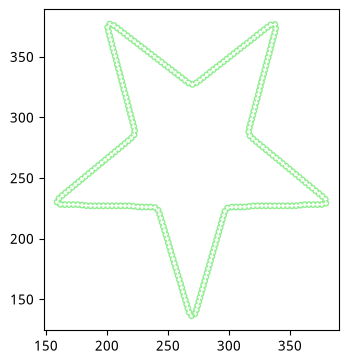

In [1]:
import numpy as np

from hbs import __version__
from hbs.plotting import plot_boundary
from hbs.utils.boundary import get_boundary

IMG = "img/example.png"
BOUND_POINTS = 250

print("hbs version:", __version__)

bound = get_boundary(IMG, BOUND_POINTS)
print("boundary:", bound.shape, "points")
print("x span [%.1f, %.1f]  y span [%.1f, %.1f]"
      % (bound[:, 0].min(), bound[:, 0].max(), bound[:, 1].min(), bound[:, 1].max()))

plot_boundary(bound)

## 2. Forward: boundary → HBS

`get_hbs_result` is the full report; `get_hbs` is the same solve returning the
four-tuple `(mu, field, welding, disk)` used by older code.

- `engine` — which forward engine ran (`"angular"` or `"zipper"`). The two never
  fall back to each other.
- `rung` — `"raw"` means the boundary you gave solved as-is. Anything else
  (`"resample500"`, `"resample500+s2"`, `"resample500+s4"`) means the engine failed
  on the raw input and a degraded resample succeeded: usable, noticeably less
  faithful, so report it.
- `gauge` — which source-circle rotation gauge was applied, and how trustworthy the
  two functionals were.
- `guard_rung` — only meaningful with `validate_reconstruction=True` (see §5).

In [2]:
from hbs import get_hbs_result

result = get_hbs_result(bound)  # method="angular", normalize="default"

print("engine      :", result.engine, "| rung:", result.rung, "| guard_rung:", result.guard_rung)
print("mesh        : %d faces, %d circle points" % (result.disk.face_num, result.disk.circle_num))
print("gauge       :", result.gauge.kind,
      "| branch:", result.gauge.branch,
      "| phase: %.2f deg" % (0.0 if result.gauge.phase is None else np.degrees(result.gauge.phase)))
print("confidence  : conf_i2=%.4f  conf_m3=%.4f  branch_margin=%.2f deg"
      % (result.gauge.confidence_i2, result.gauge.confidence_m3, np.degrees(result.gauge.branch_margin)))
print("why         :", result.gauge.reason)

mu = result.mu
abs_mu = np.abs(mu)
print("|mu|         : max %.5f, %d faces above 0.99 of %d"
      % (abs_mu.max(), int((abs_mu > 0.99).sum()), mu.size))

engine      : angular | rung: raw | guard_rung: None
mesh        : 60796 faces, 500 circle points
gauge       : default | branch: None | phase: 4.89 deg
confidence  : conf_i2=0.0023  conf_m3=0.2023  branch_margin=90.00 deg
why         : 按请求使用无分支锚 C₀（权重 1，可信度 0.00153）
|mu|         : max 0.99996, 217 faces above 0.99 of 60796


`μ` must satisfy `|μ| < 1` everywhere (`mu_chop` saturates it smoothly). On this
particular shape a few hundred of the 60 796 faces sit very close to that bound —
`μ` is *near-critical* here, which is exactly the regime where the reconstruction in
§3 gets fragile.

The three pictures below are the welding (`x` = source circle, `y` = the shape's own
circle), the `|μ|` field on the disk faces, and the harmonic extension on the mesh
vertices.

Conformal welding produced by the engine


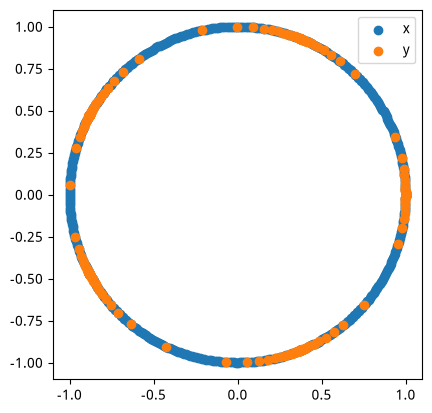

|mu| on the disk faces


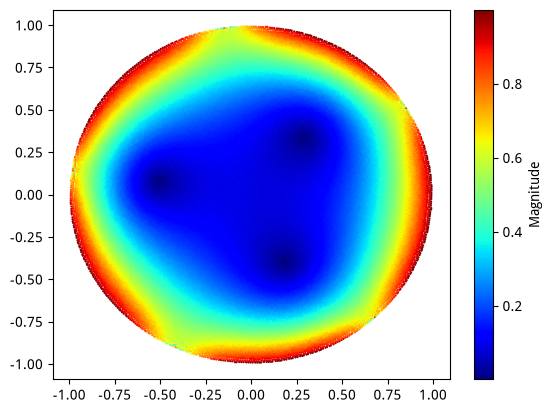

Harmonic extension (the mapping whose Beltrami coefficient is mu)


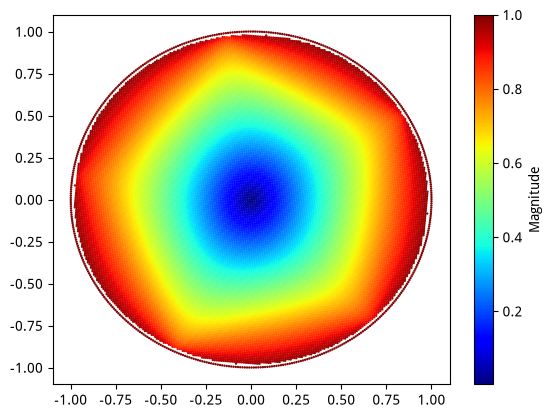

In [3]:
from hbs.plotting import plot_conformal, plot_mapping, plot_mu

print("Conformal welding produced by the engine")
plot_conformal(result.welding)

print("|mu| on the disk faces")
plot_mu(result.disk, mu)

print("Harmonic extension (the mapping whose Beltrami coefficient is mu)")
plot_mapping(result.disk, result.field)

## 3. Backward: HBS → shape

`reconstruct_from_hbs` solves a least-squares quasiconformal map (LSQC) with three
point landmarks pinned on the unit disk. Two consequences are worth internalising:

- **`disk` must be the very object `get_hbs` returned.** The gauge rotates the mesh
  vertices, so it is a *new* `DiskMesh`; a face-count mismatch makes LSQC assert.
- **`μ` is scale invariant, so the reconstruction's scale is set by the landmarks.**
  The pinned landmarks force the recovered shape's x half-axis to `1.0`; the area
  ratio to the original is `1 / rx²` (`rx` = the original x half-axis). The shape
  itself is faithful up to that uniform factor — it is *not* a welding pathology.
  Multiply by `rx` afterwards if you need absolute scale. Because of this, judge
  usability with a similarity- and orientation-invariant fidelity, never with the
  raw area ratio.

In [4]:
from hbs import reconstruct_from_hbs
from hbs.utils.boundary import smooth_resample
from hbs.utils.eval import fidelity_sim

rec_bound, rec_in, rec_out, rec_mapping = reconstruct_from_hbs(mu, result.disk)

print("reconstructed boundary:", rec_bound.shape)
print("x span [%.4f, %.4f]  y span [%.4f, %.4f]"
      % (rec_bound[:, 0].min(), rec_bound[:, 0].max(),
         rec_bound[:, 1].min(), rec_bound[:, 1].max()))

fidelity = fidelity_sim(rec_bound, smooth_resample(bound, rec_bound.shape[0]))
print("similarity-invariant fidelity: %.4f  (RMS / effective radius; < 0.10 is healthy)"
      % fidelity)

reconstructed boundary: (500, 2)
x span [-0.8172, 1.0024]  y span [-0.8393, 0.8283]
similarity-invariant fidelity: 0.0174  (RMS / effective radius; < 0.10 is healthy)


Mapping recovered by LSQC


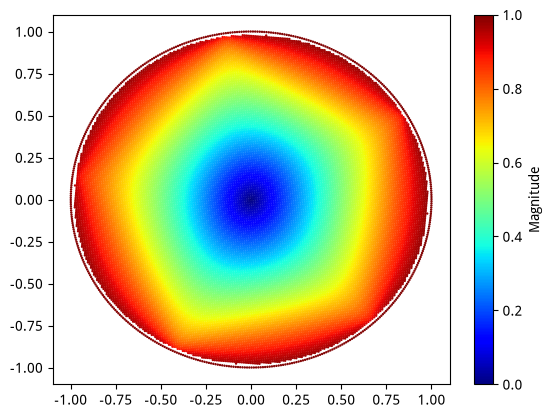

Original boundary (scale 1)


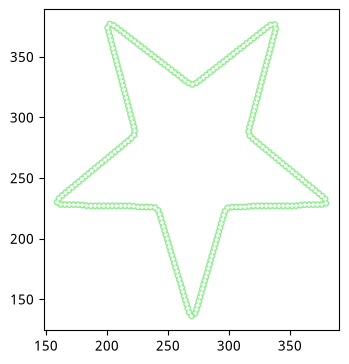

Reconstructed boundary — determined only up to a Mobius map and a uniform scale


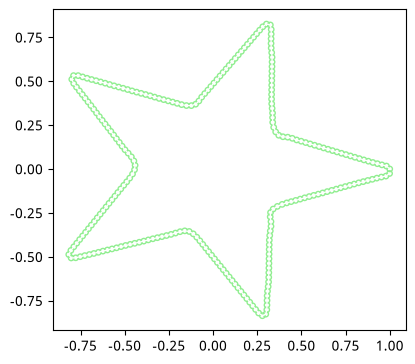

In [5]:
from hbs.plotting import plot_boundary, plot_mapping

print("Mapping recovered by LSQC")
plot_mapping(result.disk, rec_mapping)

print("Original boundary (scale 1)")
plot_boundary(smooth_resample(bound, 250), scale=1)

print("Reconstructed boundary — determined only up to a Mobius map and a uniform scale")
plot_boundary(smooth_resample(rec_bound, 250), scale=1)

## 4. The two engines, cross-checked

`"angular"` (boundary-layer logarithmic single-layer potentials) and `"zipper"`
(Bishop/Marshall zipper) are independent implementations. Their weldings differ by a
*source-circle rotation*, so comparing them naively is a trap: feeding each engine's
own `y` into the FEM reports a `μ` relative difference of ~0.8, while removing that
rotation first gives ~0.004. `compare_engines` does the alignment for you.

Pass the same explicit `disk` to both and `normalize="none"`, otherwise the two
gauges hide the difference you are trying to measure.

source-circle rotation needed to align: 198.40 deg
welding rms after that alignment     : 0.3041 deg
mu rms / mu max                      : 0.0042 / 0.1002
(mu_max is dominated by the boundary layer r > 0.97 — judge agreement by mu_rms)


Welding curve of the angular engine (x angle -> y angle)


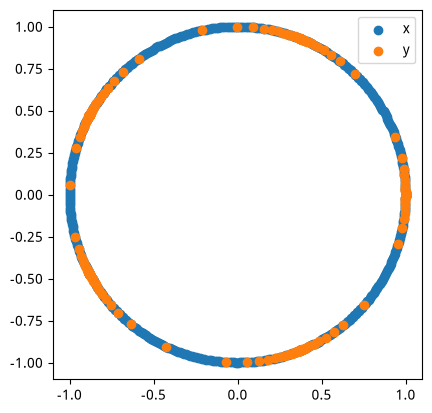

In [6]:
import hbs.cache as cache
from hbs import compare_engines, get_conformal_welding

disk, fem = cache.load_unit_disk(0.01, 500)

zipper = get_hbs_result(bound, method="zipper",  normalize="none", disk=disk)
angular = get_hbs_result(bound, method="angular", normalize="none", disk=disk)
agreement = compare_engines(zipper.welding, angular.welding, disk, fem, 500)

print("source-circle rotation needed to align: %.2f deg" % np.degrees(agreement.welding_shift))
print("welding rms after that alignment     : %.4f deg" % np.degrees(agreement.welding_rms))
print("mu rms / mu max                      : %.4f / %.4f" % (agreement.mu_rms, agreement.mu_max))
print("(mu_max is dominated by the boundary layer r > 0.97 — judge agreement by mu_rms)")

cw_angular = get_conformal_welding(bound, method="angular")
cw_zipper = get_conformal_welding(bound, method="zipper")

print("Welding curve of the angular engine (x angle -> y angle)")
plot_conformal(cw_angular)

## 5. Gauges and the optional reconstruction guard

`normalize` decides how the source circle is rotated before `μ` is reported. There
are two candidate gauges, and they are not equally well conditioned on every shape:

| value | gauge | note |
|---|---|---|
| `"default"` (default) | branch-free anchor `C₀ = M₁·conj(M₃)` | weight 1, so no 180° branch; returns `kind="none"` where `C₀` vanishes |
| `"i2"` | single anchor `I₂ = ∫μ/z dA` | no branch, continuous; near-symmetric shapes give an untrustworthy direction |
| `"m34"` | paper (5.8)+(5.9), closed form | `M₃ = ∫μ dA` fixes `T mod π`, `I₂` picks the branch |
| `"c0"` | same branch-free anchor as `"default"` | explicit spelling of `"default"` |
| `"none"` | nothing | raw engine output |

`validate_reconstruction=True` (off by default) additionally checks that the `μ`
really reconstructs to a curve: a near-critical field collapses `geodesic_welding`
onto `|z| = 1` — finite, exception-free, and *not a curve*. When that happens the
solve is redone once on `circle_point_num // 2` (floor 64); if both fail it raises
`RuntimeError` instead of handing back an unvalidated signature. It costs one extra
LSQC solve, so it is opt-in.

In [7]:
from hbs import get_hbs_result

for kind in ("default", "i2", "m34", "c0", "none"):
    gauge = get_hbs_result(bound, normalize=kind, disk=disk).gauge
    phase = "     n/a" if gauge.phase is None else "%7.2f deg" % np.degrees(gauge.phase)
    print("%-7s -> kind=%-7s phase=%s  conf_i2=%.4f  conf_m3=%.4f  margin=%5.2f deg"
          % (kind, gauge.kind, phase, gauge.confidence_i2, gauge.confidence_m3,
             np.degrees(gauge.branch_margin)))

guarded = get_hbs_result(bound, validate_reconstruction=True)
print("validate_reconstruction=True -> guard_rung:", guarded.guard_rung,
      "(None means the default mesh already reconstructed to a curve)")

default -> kind=default phase=   4.89 deg  conf_i2=0.0023  conf_m3=0.2023  margin=90.00 deg
i2      -> kind=i2      phase=-178.49 deg  conf_i2=0.0023  conf_m3=0.2023  margin= 4.86 deg


m34     -> kind=m34     phase= 176.66 deg  conf_i2=0.0023  conf_m3=0.2023  margin= 4.86 deg
c0      -> kind=c0      phase=   4.89 deg  conf_i2=0.0023  conf_m3=0.2023  margin=90.00 deg


none    -> kind=none    phase=     n/a  conf_i2=0.0000  conf_m3=0.0000  margin=90.00 deg


validate_reconstruction=True -> guard_rung: None (None means the default mesh already reconstructed to a curve)


## Where to read more

- [`README.md`](https://github.com/ChanceAroundYou/hbs_python/blob/main/README.md) —
  current behaviour, public API, installation.
- [`CHANGELOG.md`](https://github.com/ChanceAroundYou/hbs_python/blob/main/CHANGELOG.md) —
  measured solver comparisons and per-version changes.
- [PyPI](https://pypi.org/project/hbs/) — published releases.
- Paper: *Harmonic Beltrami Signature: A Novel 2D Shape Representation for Object
  Classification*, Chenran Lin, Lok Ming Lui,
  [DOI 10.1137/22M1470852](https://doi.org/10.1137/22M1470852).